# Indian E-commerce Analytics - Exploratory Data Analysis (Python)

**Data:** 7 cleaned tables (`data/cleaned/`) - 16,091 orders, 6,000 customers, 900 sellers, 1,500 products, 1,891 returns, Jan 2023 - Dec 2024.

**Business rules** (same as the SQL project)
- *Valid sale* = order is **delivered** AND payment is **approved**
- *Revenue* = sum of item `price` of valid sales (freight is separate)
- *Return rate* = return requests / delivered order lines

> Run `python python/01_clean_data.py` first to create the cleaned files.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold", "axes.titlesize": 13})

ROOT = Path.cwd().parent if Path.cwd().name == "python" else Path.cwd()
D, IMG = ROOT / "data" / "cleaned", ROOT / "images"
IMG.mkdir(exist_ok=True)

customers = pd.read_csv(D / "customers.csv")
sellers   = pd.read_csv(D / "sellers.csv")
products  = pd.read_csv(D / "products.csv")
orders    = pd.read_csv(D / "orders.csv", parse_dates=["order_purchase_timestamp"])
items     = pd.read_csv(D / "order_items.csv")
payments  = pd.read_csv(D / "payments.csv")
returns   = pd.read_csv(D / "returns.csv")

def crore(x, pos=None):          # axis label helper: 10,000,000 -> ₹1 Cr
    return f"₹{x/1e7:.1f} Cr"
def save(name):
    plt.tight_layout(); plt.savefig(IMG / name, bbox_inches="tight"); plt.show()

print({n: len(d) for n, d in dict(customers=customers, sellers=sellers, products=products,
                                  orders=orders, items=items, payments=payments, returns=returns).items()})

{'customers': 6000, 'sellers': 900, 'products': 1500, 'orders': 16091, 'items': 24986, 'payments': 16091, 'returns': 1891}


## 1. Build one analysis table
Join items with orders, customers, products, sellers and payments. `sales` = every order line; `valid` = only valid sales.

In [2]:
sales = (items
    .merge(orders, on="order_id")
    .merge(customers, on="customer_id")
    .merge(products, on="product_id")
    .merge(sellers, on="seller_id")
    .merge(payments[["order_id", "payment_method", "payment_status", "payment_installments"]], on="order_id"))
valid = sales[sales.is_valid_sale == 1]
print("Order lines:", len(sales), "| valid lines:", len(valid))

Order lines: 24986 | valid lines: 21420


## 2. Headline KPIs

In [3]:
kpi = pd.Series({
    "Total orders placed": len(orders),
    "Valid orders (delivered + paid)": valid.order_id.nunique(),
    "Revenue (₹)": valid.price.sum(),
    "Freight collected (₹)": valid.freight_value.sum(),
    "Average order value (₹)": valid.price.sum() / valid.order_id.nunique(),
    "Active customers": valid.customer_id.nunique(),
    "Units sold": len(valid),
    "Orders cancelled %": (orders.order_status == "canceled").mean() * 100,
    "Late deliveries % (delivered orders)": orders.is_late.mean() * 100,
    "Return requests per 100 delivered orders": len(returns) / (orders.order_status == "delivered").sum() * 100,
})
kpi.round(2).to_frame("value")

,value
Total orders placed,1.609100e+04
Valid orders (delivered + paid),1.380800e+04
Revenue (₹),2.871673e+08
Freight collected (₹),3.913746e+06
Average order value (₹),2.079717e+04
Active customers,5.642000e+03
Units sold,2.142000e+04
Orders cancelled %,2.810000e+00
Late deliveries % (delivered orders),5.248000e+01
Return requests per 100 delivered orders,1.339000e+01


## 3. Sales trend - monthly revenue

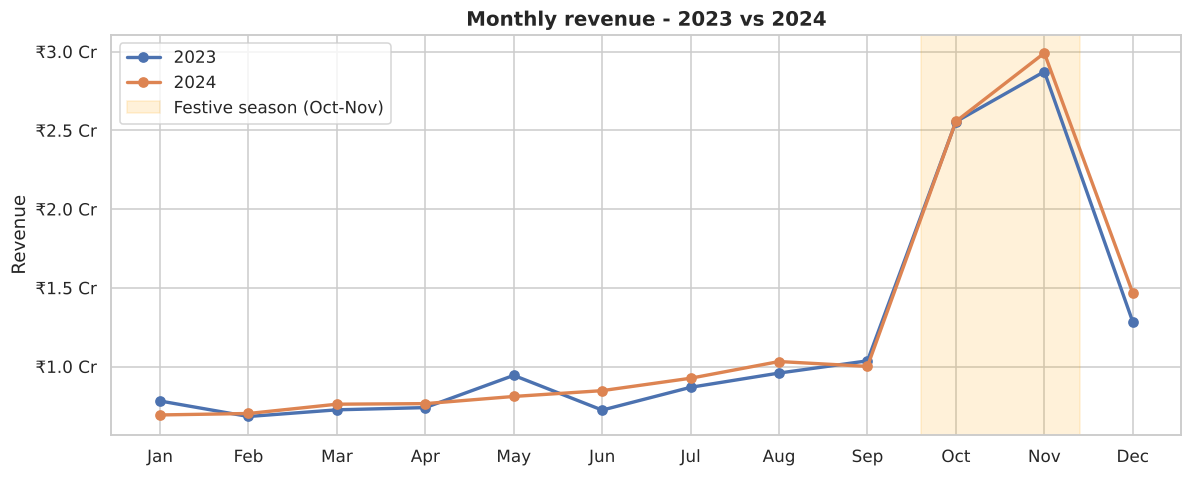

Revenue by year: {2023: 141686597.0, 2024: 145480743.0} | YoY growth: 2.68%
Festive (Oct+Nov) share of annual revenue %: {2023: 38.31, 2024: 38.13}


In [4]:
monthly = valid.groupby("order_year_month").agg(revenue=("price", "sum"), orders=("order_id", "nunique")).reset_index()
monthly["month"] = pd.to_datetime(monthly.order_year_month)
monthly["year"] = monthly.month.dt.year

fig, ax = plt.subplots(figsize=(11, 4.5))
for y, g in monthly.groupby("year"):
    ax.plot(g.month.dt.month, g.revenue, marker="o", lw=2.2, label=str(y))
ax.axvspan(9.6, 11.4, color="orange", alpha=.15, label="Festive season (Oct-Nov)")
ax.set_xticks(range(1, 13)); ax.set_xticklabels(["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"])
ax.yaxis.set_major_formatter(mtick.FuncFormatter(crore))
ax.set_title("Monthly revenue - 2023 vs 2024"); ax.set_ylabel("Revenue"); ax.legend()
save("01_monthly_revenue.png")

yr = valid.groupby("purchase_year").price.sum()
fest = valid[valid.purchase_month.isin([10, 11])].groupby("purchase_year").price.sum() / yr * 100
print("Revenue by year:", yr.round(0).to_dict(), "| YoY growth: %.2f%%" % ((yr[2024] / yr[2023] - 1) * 100))
print("Festive (Oct+Nov) share of annual revenue %:", fest.round(2).to_dict())

## 4. Categories - what makes the money?

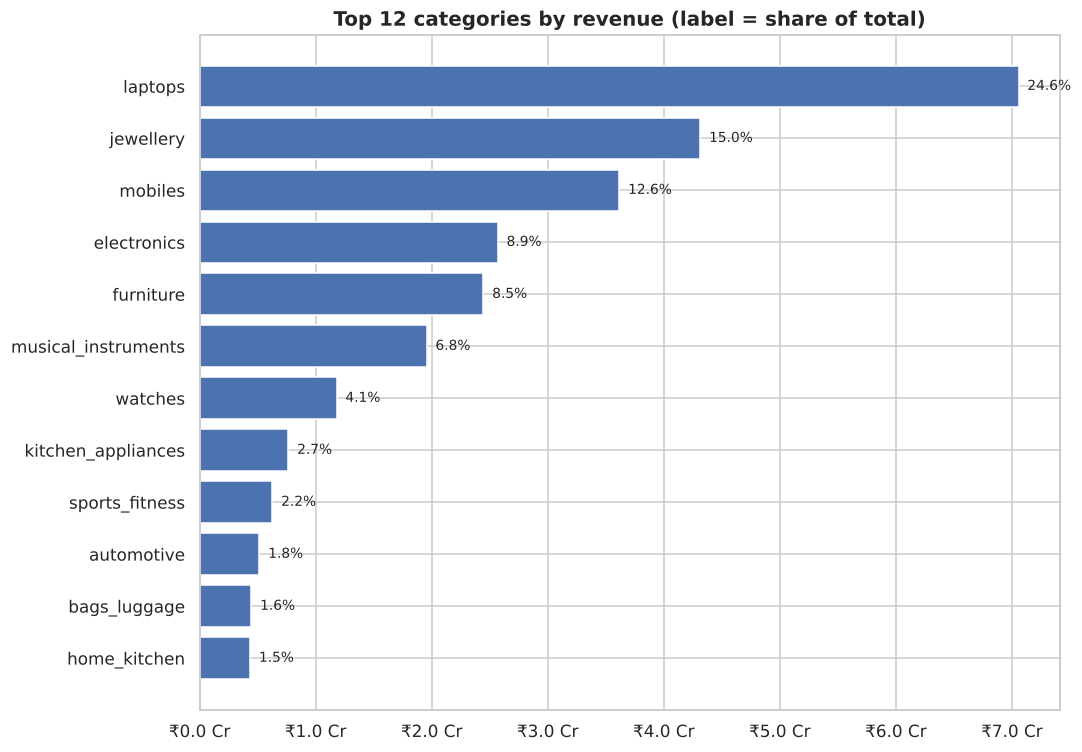

Top 3 categories share: 52.2% | top 7 share: 80.6%


,revenue,units,avg_price,pct,cum_pct
product_category_name,,,,,
laptops,70577235.0,755,93479.78,24.58,24.58
jewellery,43151949.0,861,50118.41,15.03,39.60
mobiles,36173965.0,745,48555.66,12.60,52.20
electronics,25700645.0,1005,25572.78,8.95,61.15
furniture,24461825.0,945,25885.53,8.52,69.67
musical_instruments,19572703.0,967,20240.64,6.82,76.48
watches,11811339.0,911,12965.25,4.11,80.60
kitchen_appliances,7654396.0,594,12886.19,2.67,83.26


In [5]:
cat = (valid.groupby("product_category_name")
       .agg(revenue=("price", "sum"), units=("price", "size"), avg_price=("price", "mean"))
       .sort_values("revenue", ascending=False))
cat["pct"] = cat.revenue / cat.revenue.sum() * 100
cat["cum_pct"] = cat.pct.cumsum()

fig, ax = plt.subplots(figsize=(10, 7))
top = cat.head(12).iloc[::-1]
ax.barh(top.index, top.revenue, color=sns.color_palette("deep")[0])
for i, (v, p) in enumerate(zip(top.revenue, top.pct)):
    ax.text(v, i, f"  {p:.1f}%", va="center", fontsize=9)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(crore))
ax.set_title("Top 12 categories by revenue (label = share of total)")
save("02_top_categories.png")
print("Top 3 categories share: %.1f%% | top 7 share: %.1f%%" % (cat.pct.head(3).sum(), cat.pct.head(7).sum()))
cat.head(8).round(2)

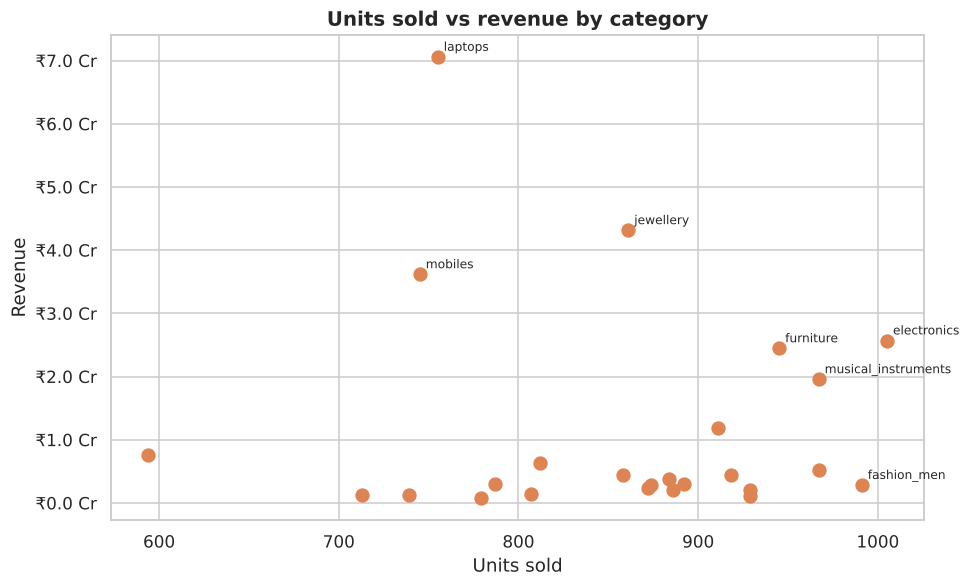

In [6]:
# Units vs revenue: cheap categories sell as many units as expensive ones
fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(cat.units, cat.revenue, s=70, color=sns.color_palette("deep")[1])
for name, r in cat.iterrows():
    if r.revenue > 1.2e7 or r.units > 990: ax.annotate(name, (r.units, r.revenue), fontsize=8, xytext=(4, 4), textcoords="offset points")
ax.yaxis.set_major_formatter(mtick.FuncFormatter(crore)); ax.set_xlabel("Units sold"); ax.set_ylabel("Revenue")
ax.set_title("Units sold vs revenue by category")
save("03_units_vs_revenue.png")

## 5. Geography - where are the customers?

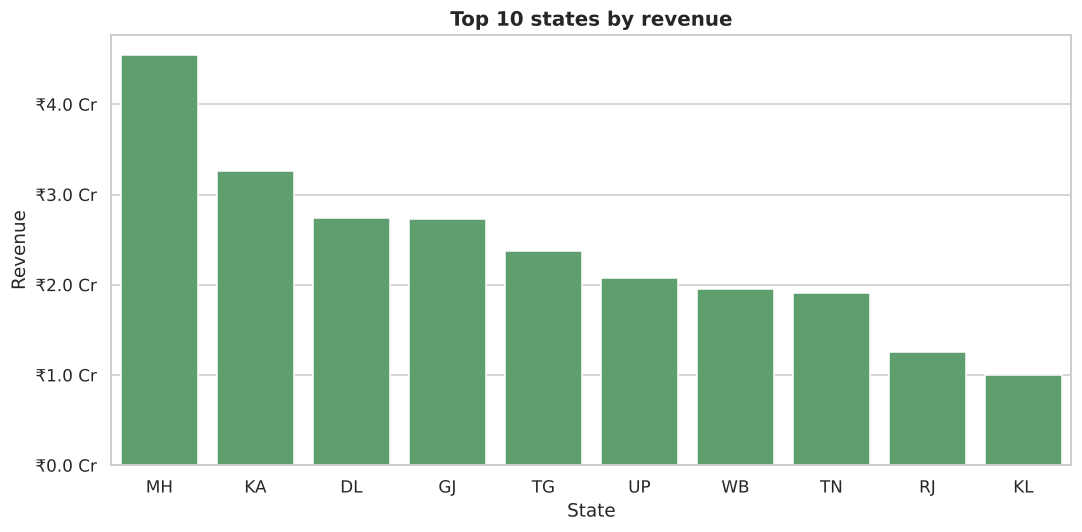

Top 5 states share of revenue: 54.4%


customer_city  customer_state
Delhi          DL                27355123.0
Mumbai         MH                24249379.0
Bengaluru      KA                24233247.0
Hyderabad      TG                22034854.0
Kolkata        WB                14481536.0
Pune           MH                14477058.0
Ahmedabad      GJ                14157476.0
Chennai        TN                12203279.0
Name: price, dtype: float64

In [7]:
state = valid.groupby("customer_state").agg(revenue=("price", "sum"), orders=("order_id", "nunique")).sort_values("revenue", ascending=False)
fig, ax = plt.subplots(figsize=(10, 5))
s = state.head(10)
sns.barplot(x=s.index, y=s.revenue, ax=ax, color=sns.color_palette("deep")[2])
ax.yaxis.set_major_formatter(mtick.FuncFormatter(crore)); ax.set_xlabel("State"); ax.set_ylabel("Revenue")
ax.set_title("Top 10 states by revenue")
save("04_top_states.png")
print("Top 5 states share of revenue: %.1f%%" % (state.revenue.head(5).sum() / state.revenue.sum() * 100))

city = valid.groupby(["customer_city", "customer_state"]).price.sum().sort_values(ascending=False).head(8)
city.round(0)

## 6. Customers - one-time vs repeat, and RFM segments

{'Repeat': 54.9, 'One-time': 45.1}
Repeat customers generate 82.1% of revenue


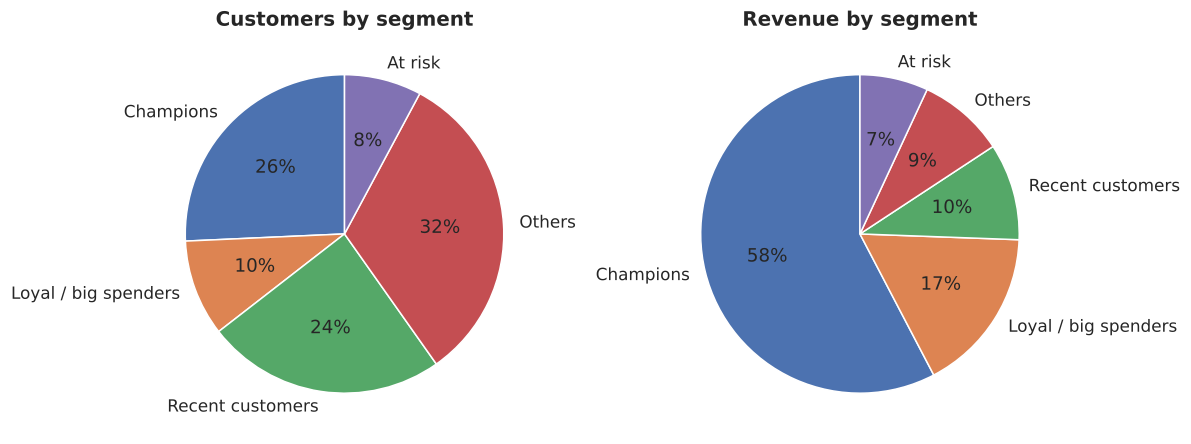

,customers,revenue,avg_spend
segment,,,
Champions,1451,165614183.0,114138.0
Loyal / big spenders,552,48093446.0,87126.0
Recent customers,1370,28244139.0,20616.0
Others,1827,25320311.0,13859.0
At risk,442,19895261.0,45012.0


In [8]:
cust = valid.groupby("customer_id").agg(orders=("order_id", "nunique"), spend=("price", "sum"),
                                       last=("order_purchase_timestamp", "max"))
cust["type"] = np.where(cust.orders == 1, "One-time", "Repeat")
print(cust.type.value_counts(normalize=True).mul(100).round(1).to_dict())
print("Repeat customers generate %.1f%% of revenue" % (cust[cust.type == "Repeat"].spend.sum() / cust.spend.sum() * 100))

# RFM-lite (same logic as the SQL query Q16)
ref = orders.order_purchase_timestamp.max().normalize() + pd.Timedelta(days=1)
cust["recency"] = (ref - cust["last"].dt.normalize()).dt.days
cust["R"] = pd.qcut(cust.recency.rank(method="first", ascending=False), 4, labels=[1, 2, 3, 4]).astype(int)
cust["F"] = pd.qcut(cust.orders.rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
cust["M"] = pd.qcut(cust.spend.rank(method="first"), 4, labels=[1, 2, 3, 4]).astype(int)
def seg(r):
    if r.R >= 3 and r.F >= 3 and r.M >= 3: return "Champions"
    if r.F >= 3 and r.M >= 3: return "Loyal / big spenders"
    if r.R >= 3: return "Recent customers"
    if r.R == 1 and (r.F >= 3 or r.M >= 3): return "At risk"
    return "Others"
cust["segment"] = cust.apply(seg, axis=1)
rfm = cust.groupby("segment").agg(customers=("spend", "size"), revenue=("spend", "sum"), avg_spend=("spend", "mean")).sort_values("revenue", ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
rfm.customers.plot.pie(ax=axes[0], autopct="%1.0f%%", startangle=90, ylabel="", title="Customers by segment")
(rfm.revenue / rfm.revenue.sum() * 100).plot.pie(ax=axes[1], autopct="%1.0f%%", startangle=90, ylabel="", title="Revenue by segment")
save("05_rfm_segments.png")
rfm.round(0)

## 7. Payments

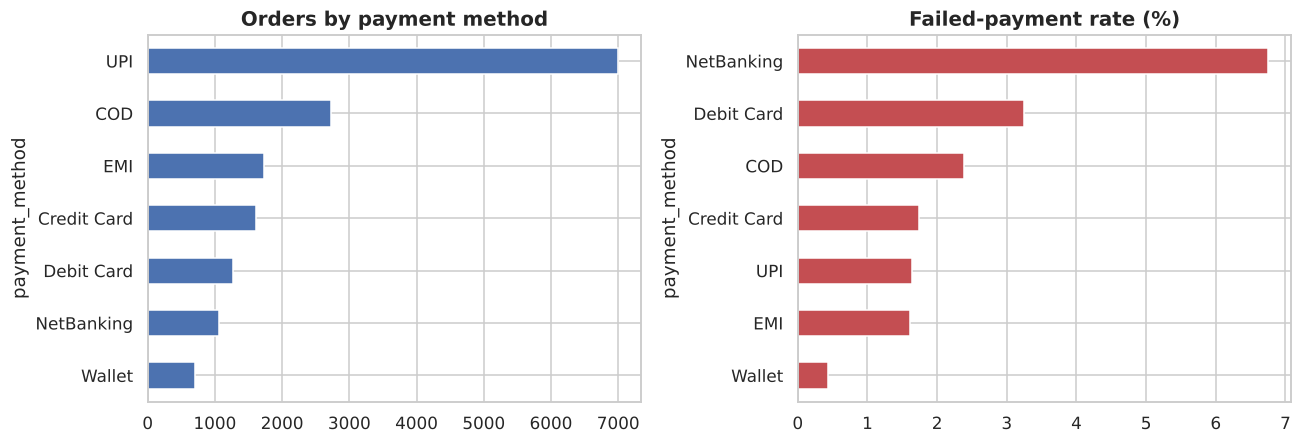

EMI share of orders by basket value (%):
{'<5k': 0.0, '5-20k': 4.5, '20-50k': 31.7, '50k+': 30.5}


In [9]:
pm = payments.groupby("payment_method").agg(orders=("payment_id", "size"), value=("payment_value", "sum"), failed=("payment_status", lambda s: (s == "failed").mean() * 100))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
pm.orders.sort_values().plot.barh(ax=axes[0], color=sns.color_palette("deep")[0]); axes[0].set_title("Orders by payment method")
pm.failed.sort_values().plot.barh(ax=axes[1], color=sns.color_palette("deep")[3]); axes[1].set_title("Failed-payment rate (%)")
save("06_payment_methods.png")

bands = pd.cut(payments.payment_value, [0, 5000, 20000, 50000, np.inf], labels=["<5k", "5-20k", "20-50k", "50k+"])
print("EMI share of orders by basket value (%):"); print(payments.assign(b=bands).groupby("b", observed=True).payment_method.apply(lambda s: (s == "EMI").mean() * 100).round(1).to_dict())

## 8. Delivery performance

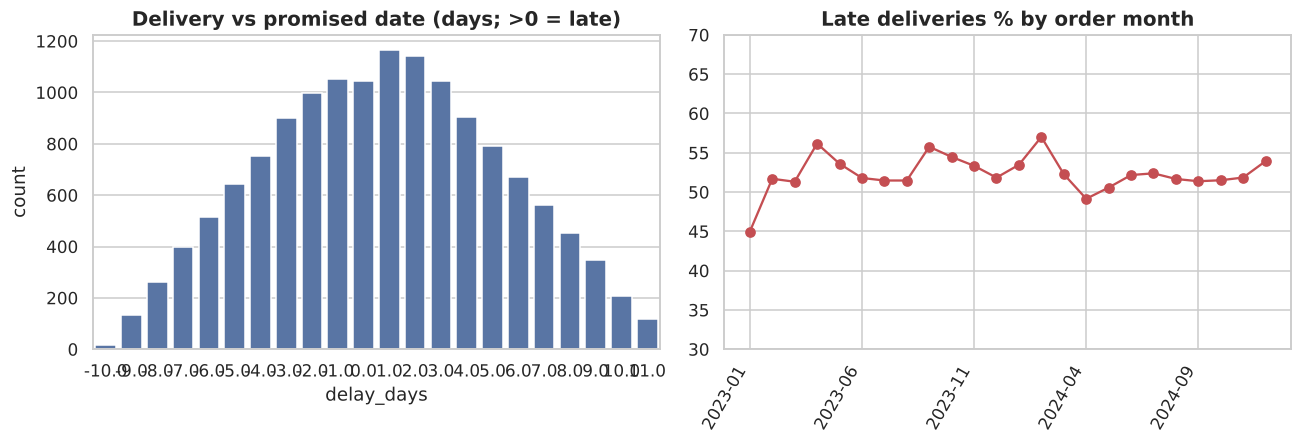

Late deliveries: 52.5% | avg delivery time: 7.8 days


In [10]:
dl = orders[orders.order_status == "delivered"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
sns.countplot(x=dl.delay_days, ax=axes[0], color=sns.color_palette("deep")[0]); axes[0].set_title("Delivery vs promised date (days; >0 = late)")
axes[0].set_xlabel("delay_days")
dl.groupby("order_year_month").is_late.mean().mul(100).plot(ax=axes[1], marker="o", color=sns.color_palette("deep")[3])
axes[1].set_title("Late deliveries % by order month"); axes[1].set_ylim(30, 70); axes[1].set_xlabel("")
plt.setp(axes[1].get_xticklabels(), rotation=60, ha="right")
save("07_delivery.png")
print("Late deliveries: %.1f%% | avg delivery time: %.1f days" % (dl.is_late.mean() * 100, dl.delivery_days.mean()))

## 9. Returns

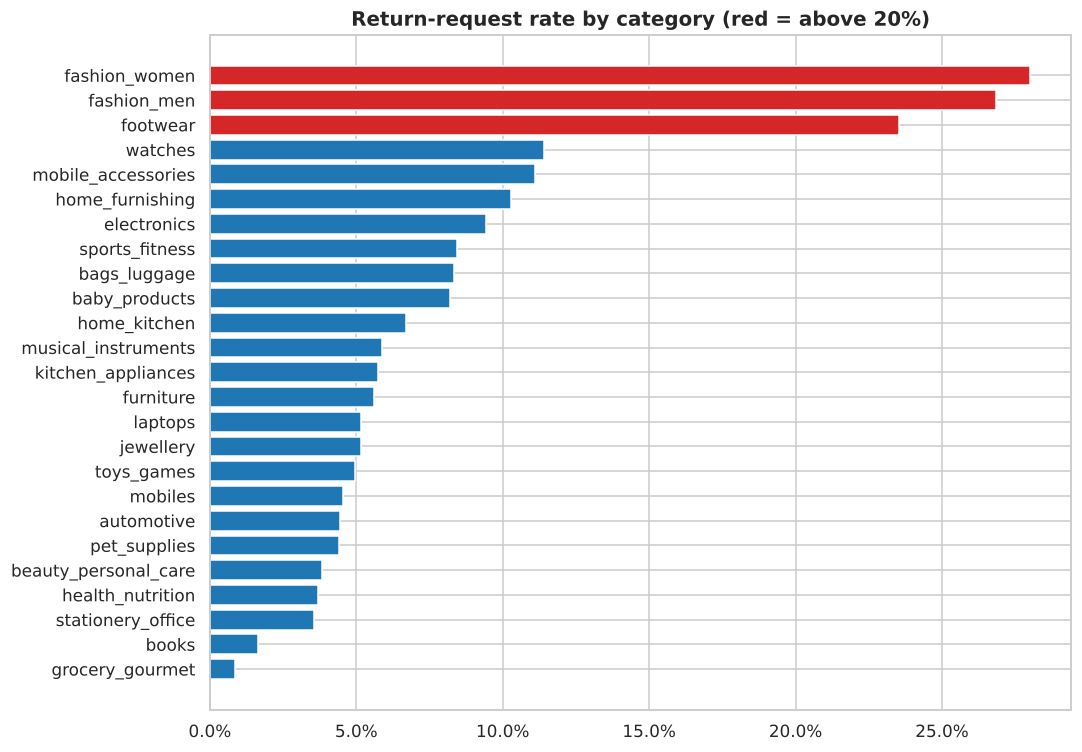

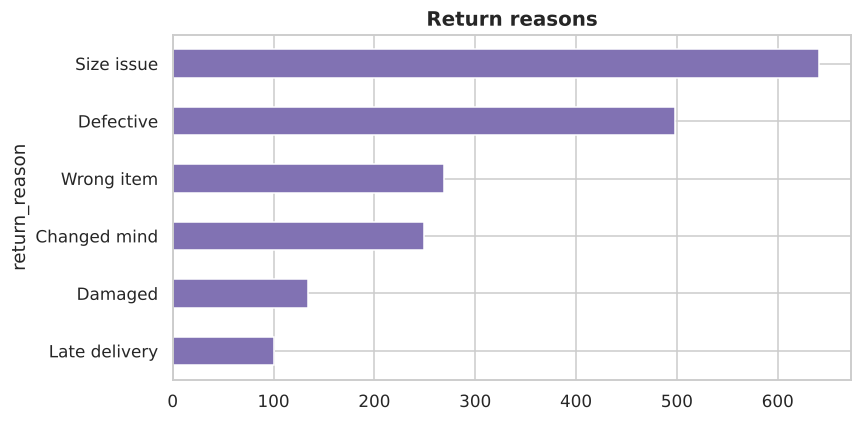

Orders with a return - late: 12.76% | on time: 12.80%
Fashion + footwear share of all returns: 37.8%


resolution_type,Not applicable,Refund,Replacement,Store credit
return_status,,,,
approved,0,813,510,276
pending,0,49,15,14
rejected,214,0,0,0


In [11]:
rc = (returns.merge(products, on="product_id").groupby("product_category_name").size().rename("returns").to_frame()
      .join(sales[sales.order_status == "delivered"].groupby("product_category_name").size().rename("units")))
rc["return_rate"] = rc.returns / rc.units * 100
rc = rc.sort_values("return_rate", ascending=False)

fig, ax = plt.subplots(figsize=(10, 7))
colors = ["#d62728" if r > 20 else "#1f77b4" for r in rc.return_rate.iloc[::-1]]
ax.barh(rc.index[::-1], rc.return_rate.iloc[::-1], color=colors)
ax.xaxis.set_major_formatter(mtick.PercentFormatter()); ax.set_title("Return-request rate by category (red = above 20%)")
save("08_return_rate_category.png")

fig, ax = plt.subplots(figsize=(8, 4))
returns.return_reason.value_counts().sort_values().plot.barh(ax=ax, color=sns.color_palette("deep")[4]); ax.set_title("Return reasons")
save("09_return_reasons.png")

# Do late deliveries cause more returns?
d = orders[orders.order_status == "delivered"].assign(has_return=lambda x: x.order_id.isin(returns.order_id))
print("Orders with a return - late: %.2f%% | on time: %.2f%%" % tuple(d.groupby("is_late").has_return.mean().mul(100)[[1, 0]]))
print("Fashion + footwear share of all returns: %.1f%%" % (returns.merge(products, on='product_id').product_category_name.isin(['fashion_women','fashion_men','footwear']).mean() * 100))
returns.groupby(["return_status", "resolution_type"]).size().unstack(fill_value=0)

## 10. Key insights

1. **Revenue ≈ ₹28.7 Cr** from 13,808 valid orders; AOV ≈ ₹20.8k. Growth 2023 → 2024 is only **+2.7%** - the business is flat year on year.
2. **Festive season drives ~38% of annual revenue** in just two months (Oct-Nov) in both years; orders jump ~2.5x versus September.
3. **Revenue is concentrated in a few high-ticket categories**: laptops (24.6%), jewellery (15.0%) and mobiles (12.6%) make ~52% of revenue, although every category sells a similar number of units (~600-1,000).
4. **Maharashtra, Karnataka, Delhi, Gujarat and Telangana** contribute the biggest share (top 5 states = 54% of revenue); Delhi, Mumbai, Bengaluru and Hyderabad are the top cities.
5. **Repeat customers are the core**: ~55% of active customers order more than once and bring ~82% of revenue.
6. **UPI is the leading method (43% of orders)**, but **EMI orders are worth ~3x more per order (₹50.8k vs ~₹17-18k)** and is used for ~30% of orders above ₹20k. NetBanking has by far the highest failed-payment rate (6.8%).
7. **More than half of the deliveries (52.5%) arrive after the promised date** - the estimated-delivery promise is not being kept. Surprisingly, late delivery does **not** change the return rate (12.8% vs 12.8%).
8. **Returns are a category problem, not a delivery problem**: fashion (men/women) and footwear have 24-28% return-request rates, driven mainly by *size issues* (34% of all returns). Books and grocery are below 2%.

## 11. Data caveats
- 313 delivered orders have a *failed* payment - excluded from revenue.
- Order timestamps look capped at 23:59 (hour 23 has ~3x the orders of hour 22), so hour-of-day analysis is not reliable.
- The returns table has no `seller_id` or return value, so returns cannot be converted into ₹ lost.
- RFM segment sizes differ by a few customers between SQL (`NTILE`) and Python (`qcut`) because ties are split differently.
- Same product can appear in one order from different sellers; seller-level return attribution uses the first matching line.